# 01 · Comprensión del negocio y de los datos

**Proyecto:** videos en tendencia de YouTube en Estados Unidos
**Metodología:** CRISP-DM, etapas 1 (comprensión del negocio) y 2 (comprensión de los datos)

Este notebook define qué quiere resolver la empresa y revisa si los datos disponibles permiten responderlo. No modifica los datos: cada problema que se encuentra aquí se convierte en una decisión de limpieza para el notebook 02.

## 1. Comprensión del negocio

### 1.1 Contexto

La empresa va a lanzar su marca en Estados Unidos y quiere posicionar un canal propio de YouTube que lleve tráfico a su página web. Antes de invertir necesita entender cómo se comportan los videos que llegan a tendencia y, más adelante, decidir si trabaja con sponsors y con cuáles.

### 1.2 Objetivos

| Objetivo de negocio | Objetivo analítico |
|---|---|
| Saber en qué tipo de contenido conviene invertir | Comparar categorías por vistas, likes y nivel de interacción |
| Identificar perfiles de video y de canal para elegir sponsors | Segmentar los videos con clustering |
| Definir qué cuidar al producir un video | Medir qué atributos se asocian con durar más en tendencia |
| Decidir cuándo publicar | Evaluar el efecto del día y la hora de publicación |
| Estimar el alcance esperado de un video | Entrenar y evaluar un modelo que prediga vistas o likes |

### 1.3 Audiencia y criterio de éxito

Los resultados se presentan a CEO, CTO, Data Manager y product managers. El análisis es útil si cada pregunta termina en una recomendación que se pueda ejecutar, y si las limitaciones de los datos quedan dichas con claridad.

## 2. Carga de los datos

Hay dos fuentes, ambas de [Kaggle](https://www.kaggle.com/datasets/datasnaek/youtube-new) y solo para Estados Unidos:

- `USvideos.csv`: datos estructurados, una fila por video y por día en tendencia.
- `US_category_id.json`: datos semiestructurados con el nombre de cada categoría.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

sys.path.append(str(Path.cwd().parent))
from src.data import RAW_DIR, FIGURES_DIR, load_categories, load_videos
from src.viz import BLUE, COMPACT, set_style

set_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.float_format", "{:,.2f}".format)

### 2.1 El JSON de categorías

El archivo viene anidado, tal como lo entrega la API de YouTube. Solo interesan el `id` y el `title` de cada elemento de `items`.

In [2]:
with open(RAW_DIR / "US_category_id.json", encoding="utf-8") as f:
    raw_json = json.load(f)

print("Claves del archivo:", list(raw_json.keys()))
print("Primer elemento de 'items':")
print(json.dumps(raw_json["items"][0], indent=2))

Claves del archivo: ['kind', 'etag', 'items']
Primer elemento de 'items':
{
  "kind": "youtube#videoCategory",
  "etag": "\"m2yskBQFythfE4irbTIeOgYYfBU/Xy1mB4_yLrHy_BmKmPBggty2mZQ\"",
  "id": "1",
  "snippet": {
    "channelId": "UCBR8-60-B28hp2BmDPdntcQ",
    "title": "Film & Animation",
    "assignable": true
  }
}


In [3]:
categories = load_categories()
print(f"{len(categories)} categorías, {categories['category_id'].duplicated().sum()} ids repetidos")
categories.head(8)

32 categorías, 0 ids repetidos


,category_id,category,assignable
0,1,Film & Animation,True
1,2,Autos & Vehicles,True
2,10,Music,True
3,15,Pets & Animals,True
4,17,Sports,True
5,18,Short Movies,False
6,19,Travel & Events,True
7,20,Gaming,True


### 2.2 El CSV de videos

In [4]:
videos = load_videos()
print(f"{videos.shape[0]:,} filas y {videos.shape[1]} columnas")
videos.head(3)

40,949 filas y 16 columnas


,video_id,trending_date,title,channel_title,category_id,publish_time,tags,views,likes,dislikes,comment_count,thumbnail_link,comments_disabled,ratings_disabled,video_error_or_removed,description
0,2kyS6SvSYSE,2017-11-14,WE WANT TO TALK ABOUT OUR MARRIAGE,CaseyNeistat,22,2017-11-13 17:13:01+00:00,SHANtell martin,748374,57527,2966,15954,https://i.ytimg.com/vi/2kyS6SvSYSE/default.jpg,False,False,False,SHANTELL'S CHANNEL - https://www.youtube.com/s...
1,1ZAPwfrtAFY,2017-11-14,The Trump Presidency: Last Week Tonight with J...,LastWeekTonight,24,2017-11-13 07:30:00+00:00,"last week tonight trump presidency|""last week ...",2418783,97185,6146,12703,https://i.ytimg.com/vi/1ZAPwfrtAFY/default.jpg,False,False,False,"One year after the presidential election, John..."
2,5qpjK5DgCt4,2017-11-14,"Racist Superman | Rudy Mancuso, King Bach & Le...",Rudy Mancuso,23,2017-11-12 19:05:24+00:00,"racist superman|""rudy""|""mancuso""|""king""|""bach""...",3191434,146033,5339,8181,https://i.ytimg.com/vi/5qpjK5DgCt4/default.jpg,False,False,False,WATCH MY PREVIOUS VIDEO ▶ \n\nSUBSCRIBE ► http...


### 2.3 Cruce de las dos fuentes

Se une por `category_id`. Si alguna fila quedara sin categoría habría que revisarlo antes de seguir.

In [5]:
df = videos.merge(categories[["category_id", "category"]], on="category_id", how="left", validate="m:1")

print("Filas sin categoría después del cruce:", df["category"].isna().sum())
print(f"Categorías en el JSON: {len(categories)} · categorías con videos: {df['category'].nunique()}")

Filas sin categoría después del cruce: 0
Categorías en el JSON: 32 · categorías con videos: 16


El cruce es completo. De las 32 categorías del JSON, solo 16 tienen videos en tendencia.

## 3. Estructura de los datos

| Columna | Qué contiene |
|---|---|
| `video_id` | Identificador del video |
| `trending_date` | Día en que el video estuvo en tendencia |
| `title`, `channel_title` | Título del video y nombre del canal |
| `category_id`, `category` | Categoría (código y nombre) |
| `publish_time` | Fecha y hora de publicación, en UTC |
| `tags` | Etiquetas separadas por `|` |
| `views`, `likes`, `dislikes`, `comment_count` | Acumulados hasta ese día de tendencia |
| `comments_disabled`, `ratings_disabled` | Si el canal desactivó comentarios o valoraciones |
| `video_error_or_removed` | Si el video fue retirado o dio error |
| `thumbnail_link`, `description` | Enlace a la miniatura y descripción |

In [6]:
summary = pd.DataFrame(
    {
        "tipo": df.dtypes.astype(str),
        "nulos": df.isna().sum(),
        "% nulos": df.isna().mean() * 100,
        "valores únicos": df.nunique(),
    }
)
summary

,tipo,nulos,% nulos,valores únicos
video_id,object,0,0.00,6351
trending_date,datetime64[ns],0,0.00,205
title,object,0,0.00,6455
channel_title,object,0,0.00,2207
category_id,int64,0,0.00,16
publish_time,"datetime64[ns, UTC]",0,0.00,6269
tags,object,0,0.00,6055
views,int64,0,0.00,40478
likes,int64,0,0.00,29850
dislikes,int64,0,0.00,8516


## 4. Unidad de análisis: una fila no es un video

El dato más importante para todo lo que sigue es que cada video aparece una vez por cada día que estuvo en tendencia.

In [7]:
n_videos = df["video_id"].nunique()
days_per_video = df.groupby("video_id")["trending_date"].nunique()

print(f"Filas: {len(df):,}")
print(f"Videos únicos: {n_videos:,}")
print(f"Canales únicos: {df['channel_title'].nunique():,}")
print(f"Días en tendencia por video: mediana {days_per_video.median():.0f}, "
      f"promedio {days_per_video.mean():.1f}, máximo {days_per_video.max()}")
print(f"Videos con un solo día en tendencia: {(days_per_video == 1).mean():.1%}")

Filas: 40,949
Videos únicos: 6,351
Canales únicos: 2,207
Días en tendencia por video: mediana 6, promedio 6.4, máximo 29
Videos con un solo día en tendencia: 11.1%


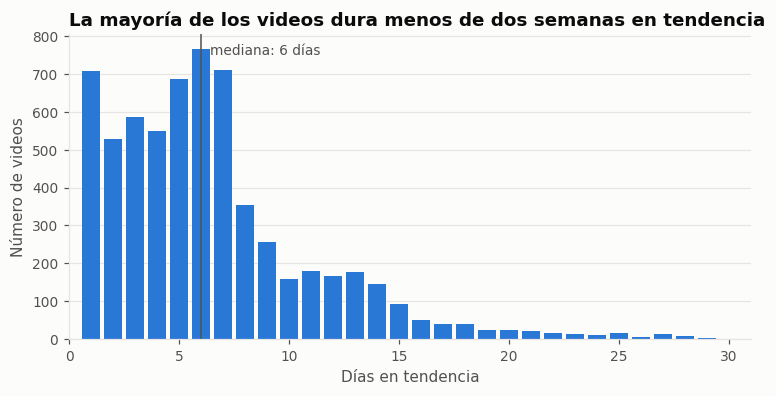

In [8]:
counts = days_per_video.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.6))
ax.bar(counts.index, counts.values, color=BLUE, width=0.8)
ax.axvline(days_per_video.median(), color="#52514e", linewidth=1)
ax.annotate(f"mediana: {days_per_video.median():.0f} días",
            xy=(days_per_video.median(), counts.max()), xytext=(6, -4),
            textcoords="offset points", fontsize=9, color="#52514e")
ax.set_title("La mayoría de los videos dura menos de dos semanas en tendencia")
ax.set_xlabel("Días en tendencia")
ax.set_ylabel("Número de videos")
ax.set_xlim(0, 31)
fig.savefig(FIGURES_DIR / "01_dias_en_tendencia.png")
plt.show()

Las 40.949 filas corresponden a 6.351 videos. Si se analizara por fila, un video que duró 20 días pesaría 20 veces más que uno que duró un día, y las vistas se contarían varias veces. Por eso el análisis se hará **a nivel de video**.

### 4.1 Las métricas son acumuladas y crecen día a día

In [9]:
ordered = df.sort_values(["video_id", "trending_date"])
first = ordered.groupby("video_id").first()
last = ordered.groupby("video_id").last()

growth = (last["views"] / first["views"])[days_per_video > 1]
print(f"Entre su primer y último día en tendencia, las vistas de un video se multiplican "
      f"por {growth.median():.2f} (mediana); el 10% superior, por más de {growth.quantile(0.9):.1f}.")

example = ordered[ordered["video_id"] == days_per_video.idxmax()]
example[["trending_date", "title", "views", "likes", "comment_count"]].iloc[[0, 1, 2, -1]]

Entre su primer y último día en tendencia, las vistas de un video se multiplican por 1.74 (mediana); el 10% superior, por más de 5.0.


,trending_date,title,views,likes,comment_count
33750,2018-05-10,Sam Smith - Pray (Official Video) ft. Logic,641944,72641,4357
33952,2018-05-11,Sam Smith - Pray (Official Video) ft. Logic,2174315,148686,7907
34164,2018-05-12,Sam Smith - Pray (Official Video) ft. Logic,3117295,184871,8916
39747,2018-06-08,Sam Smith - Pray (Official Video) ft. Logic,20934803,359012,12451


Las vistas y los likes son fotos acumuladas. Para comparar videos hay que elegir un momento: el primer día en tendencia (cómo llegó) o el último (cuánto alcanzó).

### 4.2 ¿Cambian los atributos de un mismo video?

In [10]:
attrs = ["title", "channel_title", "category_id", "tags", "description", "publish_time"]
changes = ordered.groupby("video_id")[attrs].nunique(dropna=False).gt(1).mean().mul(100)
changes.rename("% de videos donde el atributo cambia").to_frame()

,% de videos donde el atributo cambia
title,1.72
channel_title,0.19
category_id,0.27
tags,3.01
description,9.90
publish_time,0.03


La descripción cambia en cerca del 10% de los videos y las etiquetas en el 3%; el título y la categoría casi nunca. Al consolidar por video se tomará el valor del primer día en tendencia, que es el que tenía el video cuando llegó.

## 5. Cobertura temporal

In [11]:
calendar = pd.date_range(df["trending_date"].min(), df["trending_date"].max())
missing_days = calendar.difference(df["trending_date"].unique())
per_day = df.groupby("trending_date").size()

print(f"Periodo: {calendar.min():%d-%m-%Y} a {calendar.max():%d-%m-%Y} ({len(calendar)} días calendario)")
print(f"Días con datos: {df['trending_date'].nunique()} · días sin datos: {len(missing_days)}")
print("Días faltantes:", ", ".join(missing_days.strftime("%d-%m-%Y")))
print(f"Videos por día: mínimo {per_day.min()}, máximo {per_day.max()}")

Periodo: 14-11-2017 a 14-06-2018 (213 días calendario)
Días con datos: 205 · días sin datos: 8
Días faltantes: 10-01-2018, 11-01-2018, 08-04-2018, 09-04-2018, 10-04-2018, 11-04-2018, 12-04-2018, 13-04-2018
Videos por día: mínimo 196, máximo 200


In [12]:
publish_date = first["publish_time"].dt.tz_localize(None).dt.normalize()
delay = (first["trending_date"] - publish_date).dt.days

print("Días entre la publicación y el primer día en tendencia (por video):")
print(delay.quantile([0.25, 0.5, 0.75, 0.9, 0.95, 0.99]).rename("días").to_frame().T.to_string())
print(f"\nVideos que tardaron más de 30 días: {(delay > 30).sum()} ({(delay > 30).mean():.1%})")
print(f"Publicación más antigua: {first['publish_time'].min():%d-%m-%Y}")

Días entre la publicación y el primer día en tendencia (por video):
      0.25  0.50  0.75  0.90  0.95   0.99
días  1.00  2.00  3.00  4.00  6.00 527.00

Videos que tardaron más de 30 días: 101 (1.6%)
Publicación más antigua: 23-07-2006


Tres consecuencias:

- **Solo hay siete meses** (noviembre de 2017 a junio de 2018). No se puede medir estacionalidad anual; sí el efecto del día de la semana, la hora y el mes dentro de ese periodo.
- **Faltan ocho días** (dos en enero y seis en abril de 2018). Los "días en tendencia" de los videos activos en esas fechas quedan subcontados.
- **El 95% de los videos llega a tendencia en seis días o menos** desde su publicación. Un 1,6% son videos antiguos que resurgen, algunos publicados desde 2006; se tratarán como casos atípicos.

## 6. Calidad de los datos

### 6.1 Duplicados

In [13]:
full_dups = df.duplicated().sum()
key_dups = df.duplicated(["video_id", "trending_date"]).sum()
print(f"Filas idénticas repetidas: {full_dups}")
print(f"Filas repetidas por video y día: {key_dups}")

Filas idénticas repetidas: 48
Filas repetidas por video y día: 50


Hay 48 filas idénticas y 2 más que repiten video y día con valores distintos. Se dejará una fila por video y día.

### 6.2 Valores nulos y valores que funcionan como nulos

In [14]:
quality = pd.Series(
    {
        "Descripción nula": df["description"].isna().sum(),
        "Etiquetas vacías ('[none]')": (df["tags"] == "[none]").sum(),
        "Valoraciones desactivadas": df["ratings_disabled"].sum(),
        "Likes = 0": (df["likes"] == 0).sum(),
        "Likes = 0 con valoraciones desactivadas": ((df["likes"] == 0) & df["ratings_disabled"]).sum(),
        "Comentarios desactivados": df["comments_disabled"].sum(),
        "Comentarios = 0": (df["comment_count"] == 0).sum(),
        "Comentarios = 0 con comentarios desactivados": ((df["comment_count"] == 0) & df["comments_disabled"]).sum(),
        "Video retirado o con error (filas)": df["video_error_or_removed"].sum(),
        "Video retirado o con error (videos)": df.loc[df["video_error_or_removed"], "video_id"].nunique(),
    },
    name="filas",
).to_frame()
quality["% del total"] = quality["filas"] / len(df) * 100
quality

,filas,% del total
Descripción nula,570,1.39
Etiquetas vacías ('[none]'),1535,3.75
Valoraciones desactivadas,169,0.41
Likes = 0,172,0.42
Likes = 0 con valoraciones desactivadas,169,0.41
Comentarios desactivados,633,1.55
Comentarios = 0,760,1.86
Comentarios = 0 con comentarios desactivados,633,1.55
Video retirado o con error (filas),23,0.06
Video retirado o con error (videos),4,0.01


- La única columna con nulos es `description`. Las etiquetas vacías vienen marcadas como `[none]`, no como nulo.
- Casi todos los ceros en likes y comentarios se explican porque el canal **desactivó** esa función. Ahí el cero no significa "a nadie le gustó", sino "no se pudo medir", y se tratará como dato faltante.
- Solo 4 videos aparecen como retirados o con error; se excluirán.

## 7. Distribución de las métricas

In [15]:
metrics = ["views", "likes", "dislikes", "comment_count"]
stats = last[metrics].describe(percentiles=[0.25, 0.5, 0.75, 0.99]).T
stats["asimetría"] = last[metrics].skew()
stats[["mean", "50%", "75%", "99%", "max", "asimetría"]]

,mean,50%,75%,99%,max,asimetría
views,"1,962,117.24","518,107.00","1,473,581.50","25,189,198.00","225,211,923.00",14.16
likes,"55,575.05","11,906.00","38,428.50","806,986.00","5,613,827.00",12.52
dislikes,"3,067.15",444.00,"1,507.00","34,422.50","1,674,420.00",44.91
comment_count,"6,450.74","1,266.00","4,061.50","78,741.00","1,361,580.00",24.10


El 1% de los videos con más vistas concentra el 28% de todas las vistas.


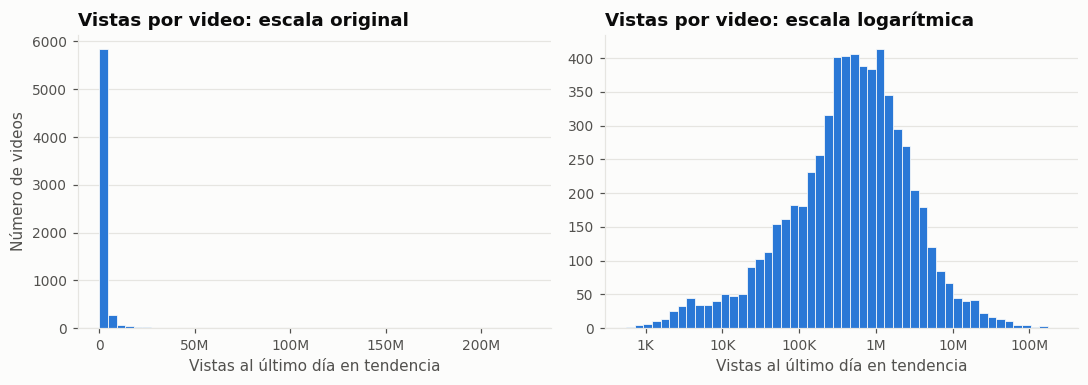

In [16]:
top1 = last["views"].nlargest(int(len(last) * 0.01)).sum() / last["views"].sum()
print(f"El 1% de los videos con más vistas concentra el {top1:.0%} de todas las vistas.")

fig, axes = plt.subplots(1, 2, figsize=(10, 3.6))
axes[0].hist(last["views"], bins=50, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[0].set_title("Vistas por video: escala original")
axes[0].set_xlabel("Vistas al último día en tendencia")
axes[0].set_ylabel("Número de videos")
axes[0].xaxis.set_major_formatter(COMPACT)

axes[1].hist(np.log10(last["views"]), bins=50, color=BLUE, edgecolor="#fcfcfb", linewidth=0.5)
axes[1].set_title("Vistas por video: escala logarítmica")
axes[1].set_xlabel("Vistas al último día en tendencia")
axes[1].set_xticks(range(3, 9))
axes[1].set_xticklabels(["1K", "10K", "100K", "1M", "10M", "100M"])
fig.tight_layout()
fig.savefig(FIGURES_DIR / "01_distribucion_vistas.png")
plt.show()

Unos pocos videos tienen cientos de millones de vistas y la gran mayoría está por debajo de dos millones, así que el promedio no representa al video típico. En el análisis se usará la **mediana** para comparar, y el **logaritmo** de las métricas para los modelos.

### 7.1 Relación entre las métricas

In [17]:
last[metrics].corr(method="spearman").style.format("{:.2f}").background_gradient(cmap="Blues", vmin=0.5, vmax=1)

,views,likes,dislikes,comment_count
views,1.00,0.87,0.86,0.82
likes,0.87,1.00,0.81,0.87
dislikes,0.86,0.81,1.00,0.85
comment_count,0.82,0.87,0.85,1.00


Vistas, likes, dislikes y comentarios se mueven juntos (correlación de 0,8 o más) y se miden el mismo día. Usar los likes para "predecir" las vistas daría un modelo muy preciso pero inútil: cuando se conocen los likes ya se conocen las vistas. El modelo predictivo tendrá que apoyarse en lo que se sabe **antes** (categoría, canal, título, etiquetas, momento de publicación) o en las cifras del **primer día** para proyectar el resultado final.

## 8. Conclusiones y decisiones para la preparación

### Lo que los datos permiten y lo que no

| Pregunta | ¿Se puede responder? | Cómo se abordará |
|---|---|---|
| Categorías con más vistas y likes | Sí | Mediana por video, no suma por fila |
| Agrupaciones de videos | Sí | Clustering sobre el dataset a nivel video |
| Qué hace tendencia a un video | Parcialmente | El dataset solo contiene videos que **sí** fueron tendencia, así que no hay con qué compararlos. Se medirá qué se asocia con durar más días y con llegar más rápido |
| Influencia de la fecha | Parcialmente | Día de la semana, hora y mes. Sin estacionalidad anual: solo hay siete meses |
| Predecir vistas o likes | Sí, con cuidado | Sin usar métricas simultáneas como predictores |

### Decisiones de limpieza para el notebook 02

1. Eliminar filas duplicadas y dejar una por video y día.
2. Excluir los 4 videos retirados o con error.
3. Construir un dataset con **una fila por video**: atributos del primer día, métricas del primer y del último día, y número de días en tendencia.
4. Tratar likes y comentarios como faltantes cuando el canal los desactivó.
5. Convertir `[none]` en etiquetas vacías y los nulos de descripción en texto vacío.
6. Pasar `publish_time` de UTC a hora de Estados Unidos antes de extraer día y hora.
7. Marcar los videos que tardaron más de 30 días en llegar a tendencia.
8. Crear variables en logaritmo para vistas, likes, dislikes y comentarios.